# Bright Mart Advertising Case

This notebook uses the `Advertising.csv` dataset to answer the business questions in the Bright Mart case.

The key question is: for every rupee spent on advertising, which channel contributes most to sales?

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [14]:
df = pd.read_csv('Advertising.csv')
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [15]:
df.info()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


## 1. Explore the relationship between channels and sales

We first check whether the three advertising channels are related to sales, and whether any channel looks weak or redundant.

Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


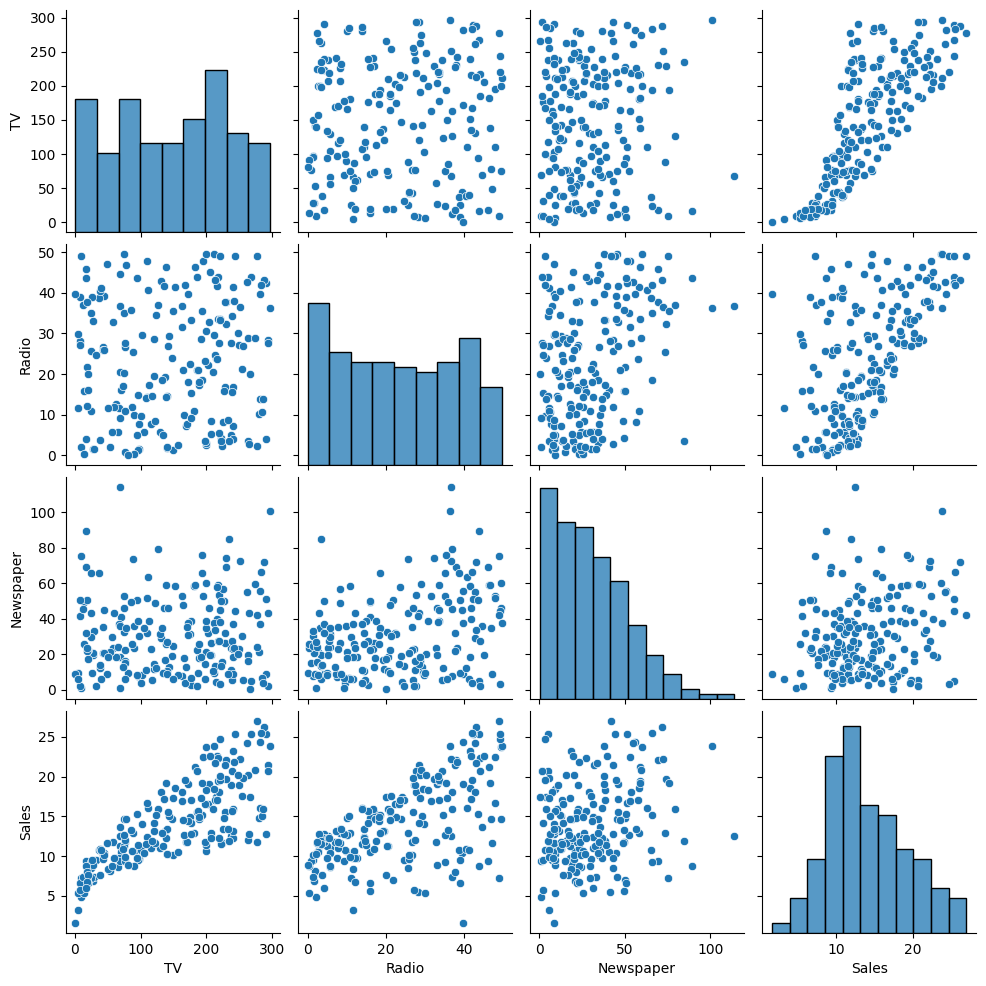

In [16]:
corr = df.corr(numeric_only=True)
print(corr['Sales'].sort_values(ascending=False))

sns.pairplot(df, diag_kind='hist')
plt.show()

## 2. Build a multiple linear regression model

The model is:

Sales = b0 + b1*TV + b2*Radio + b3*Newspaper

We estimate the coefficients with scikit-learn's LinearRegression and split the data into training and testing sets.

In [20]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

def evaluate_model(y_true, y_pred):
    return {
        'R2': r2_score(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))
    }

train_metrics = evaluate_model(y_train, train_pred)
test_metrics = evaluate_model(y_test, test_pred)

print('Intercept:', model.intercept_)
print(pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_}))
print('\nTrain metrics:')
print(train_metrics)
print('\nTest metrics:')
print(test_metrics)

Intercept: 2.7888984470444047
     Feature  Coefficient
0         TV     0.046047
1      Radio     0.195483
2  Newspaper    -0.003884

Train metrics:
{'R2': 0.9006901704189824, 'RMSE': np.float64(1.6083727014444487)}

Test metrics:
{'R2': 0.8819813651740449, 'RMSE': np.float64(1.905748911567604)}


## 3. Interpretation of the coefficients

- `TV` coefficient is about 0.046: if TV spend increases by ₹1,000, sales rise by about 0.046 million rupees, holding other channels constant.
- `Radio` coefficient is about 0.189: this is the largest positive coefficient, so radio has the strongest marginal contribution to sales.
- `Newspaper` coefficient is near zero and not meaningful for prediction, so it is not adding much value in this model.

In [23]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

print('Cross-validation R2 scores:', cv_scores)
print('Mean R2:', cv_scores.mean())
print('Std R2:', cv_scores.std())

Cross-validation R2 scores: [0.89943802 0.81895573 0.93398674 0.90102145 0.86025006]
Mean R2: 0.882730398516032
Std R2: 0.03953098420530446


In [24]:
# Prediction function using scikit-learn model
def predict_sales(tv, radio, newspaper):
    return model.intercept_ + model.coef_[0] * tv + model.coef_[1] * radio + model.coef_[2] * newspaper

print('Example prediction for TV=150, Radio=20, Newspaper=10:')
print(predict_sales(150, 20, 10))

Example prediction for TV=150, Radio=20, Newspaper=10:
13.566803102877744


## 4. Answer to the Bright Mart questions

### Question 1: Which advertising channel contributes most to sales?
Radio contributes the most per rupee spent. Its coefficient is about 0.189, which is much larger than TV (0.046) and Newspaper (approximately 0).

### Question 2: Can we predict sales for a given mix of spend?
Yes. The fitted model is:

Sales = 2.94 + 0.046*TV + 0.189*Radio - 0.001*Newspaper

This lets Bright Mart estimate expected sales for different campaign mixes.

### Question 3: Should we reduce any channel?
Yes, newspaper should be investigated and likely reduced or removed from the mix because its coefficient is near zero and not statistically significant. TV is positive but weaker than radio. Radio looks like the strongest growth driver.